# Grammar Scoring Engine for Spoken Audio: Report

## 1. Approach
Spoken audio (45-60 s) is converted into three complementary views: a transcript (Whisper ASR), acoustic/fluency features (librosa) and speech embeddings (WavLM). Regression models predict a continuous grammar score in [0, 5]. Predictions from several models are blended.

## 2. Preprocessing
- Audio loaded at 16 kHz, mono
- Whisper ASR with `temperature=0`, English; fillers and repetitions preserved so grammar errors are not auto-corrected
- ASR confidence features: avg log-prob, min log-prob, no-speech prob, compression ratio, number of segments
- Acoustic features: pauses, speech rate, duration (librosa)
- Text features: lexical, syntactic, disfluency (fillers, connectives)
- Missing/failed transcripts handled with safe defaults

## 3. Pipeline Architecture
1. Whisper → transcript + ASR confidence features
2. Acoustic / fluency features (librosa)
3. Hand-crafted text features + transformer text embeddings
4. WavLM speech embeddings
5. Models: Ridge, SVR, LightGBM on different feature views (PCA-compressed embeddings for the tree model)
6. Non-negative least squares blend of out-of-fold predictions, clipped to [0, 5]

## 5. Interpretation of Results
The OOF scatter plot (true vs predicted) shows predictions track true scores closely (r = 0.904). Extremes (0 and 5) are predicted accurately; mid-range scores (2-4) show more spread because adjacent grammar levels are harder to separate. Evaluation metrics are in Section 4.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_42.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_81.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_72.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

In [2]:
import subprocess, sys
def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
 
pip("openai-whisper", "sentence-transformers", "lightgbm")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 13.1 MB/s eta 0:00:00


In [3]:
import os, re, gc, json, difflib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import librosa
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from scipy.optimize import nnls
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error
import lightgbm as lgb


In [4]:

warnings.filterwarnings("ignore")
 
CFG = dict(
    whisper_model="turbo",          # "large-v3" is a bit more accurate but ~5x slower
    gec_model="vennify/t5-base-grammar-correction",
    text_models=["sentence-transformers/all-mpnet-base-v2", "BAAI/bge-large-en-v1.5"],
    audio_model="microsoft/wavlm-base-plus",
    use_gec=True,
    use_audio_emb=True,
    use_languagetool=True,          # needs Java; silently skipped if unavailable
    n_splits=5,
    n_repeats=3,
    seed=42,
    sr=16000,
)

In [5]:
WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])


Device: cuda


In [6]:
# %% Locate data (works whatever the folder layout of the dataset is)
INPUT = Path("/kaggle/input")
csv_files = {p.name: p for p in INPUT.rglob("*.csv")}
train_df = pd.read_csv(csv_files["train.csv"])
test_df = pd.read_csv(csv_files["test.csv"])
 

In [7]:
wav_dirs = {}
for p in INPUT.rglob("*.wav"):
    wav_dirs.setdefault(p.parent, set()).add(p.name)
 

In [8]:
def pick_dir(split, names):
    cands = [d for d in wav_dirs if split in str(d).lower()] or list(wav_dirs)
    return max(cands, key=lambda d: len(wav_dirs[d] & set(names)))

In [9]:
train_dir = pick_dir("train", train_df.filename)
test_dir = pick_dir("test", test_df.filename)
train_df["path"] = [str(train_dir / f) for f in train_df.filename]
test_df["path"] = [str(test_dir / f) for f in test_df.filename]
for name, df in [("train", train_df), ("test", test_df)]:
    missing = (~df.path.map(os.path.exists)).sum()
    print(f"{name}: {len(df)} rows, dir={df.path.iloc[0].rsplit('/', 1)[0]}, missing files={missing}")
y = train_df.label.values.astype(float)
print(train_df.label.value_counts().sort_index())
 

train: 769 rows, dir=/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train, missing files=0
test: 216 rows, dir=/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test, missing files=0
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


In [10]:
import subprocess, sys
def pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)


In [11]:
import socket
print(socket.gethostbyname("pypi.org"))   # prints an IP address = internet works

151.101.64.223


In [12]:
pip("openai-whisper", "sentence-transformers", "lightgbm")

In [13]:

# %% 1) ASR with Whisper (cached)
import whisper
 

In [14]:
ASR_PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. So, uh, I I went there."
 

In [15]:

def transcribe(df, split):
    cache = WORK / f"asr_{split}.csv"
    if cache.exists():
        return pd.read_csv(cache).fillna({"text": ""})
    part = WORK / f"asr_{split}_part.pkl"
    rows = pd.read_pickle(part) if part.exists() else []
    model = whisper.load_model(CFG["whisper_model"], device=DEVICE)
    paths = list(df.path)
    for i in tqdm(range(len(rows), len(paths)), desc=f"ASR {split}",
                  initial=len(rows), total=len(paths)):
        try:
            audio = whisper.load_audio(paths[i])[:16000 * 90]   # max 90 sec
            r = model.transcribe(audio, language="en", task="transcribe",
                                 temperature=0.0, fp16=(DEVICE == "cuda"),
                                 initial_prompt=ASR_PROMPT,
                                 condition_on_previous_text=False)
            segs = r["segments"]
            rows.append(dict(
                text=r["text"].strip(),
                asr_logprob=np.mean([s["avg_logprob"] for s in segs]) if segs else -3.0,
                asr_min_logprob=np.min([s["avg_logprob"] for s in segs]) if segs else -3.0,
                asr_nospeech=np.mean([s["no_speech_prob"] for s in segs]) if segs else 1.0,
                asr_compression=np.mean([s["compression_ratio"] for s in segs]) if segs else 0.0,
                asr_nsegs=len(segs),
            ))
        except Exception as e:
            print("fail", i, paths[i], e)
            rows.append(dict(text="", asr_logprob=-3.0, asr_min_logprob=-3.0,
                             asr_nospeech=1.0, asr_compression=0.0, asr_nsegs=0))
        if len(rows) % 50 == 0:
            pd.to_pickle(rows, part)
    out = pd.DataFrame(rows)
    out.to_csv(cache, index=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    return out
 

In [16]:
asr_tr = transcribe(train_df, "train")
asr_te = transcribe(test_df, "test")
train_df["text"], test_df["text"] = asr_tr.text.values, asr_te.text.values
for i in range(3):
    print(f"[{y[i]}] {train_df.text.iloc[i][:200]}")
 

100%|█████████████████████████████████████| 1.51G/1.51G [01:30<00:00, 17.9MiB/s]


ASR train:   0%|          | 0/769 [00:00<?, ?it/s]

ASR test:   0%|          | 0/216 [00:00<?, ?it/s]

[3.0] Well, the playground is very, very beautiful and fun. There are, there are playtons like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, um, it's more like a ga
[3.0] The scene of a school playground. Our playground looks like a very big playground having a more more greenery trees. In which we students like to garden more trees to have a fresh air and all having a
[3.5] My favorite place to visit is the beach. I love the sound of the waves crashing against the shore. The feeling of the sand between my toys and the smell of the salt water. I love the fact that there i


In [17]:

# %% 2) Acoustic / fluency features (cached)
def acoustic_features(df, split):
    cache = WORK / f"acoustic_{split}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    rows = []
    for path in tqdm(df.path, desc=f"acoustic {split}"):
        yw, sr = librosa.load(path, sr=CFG["sr"], mono=True)
        dur = len(yw) / sr
        iv = librosa.effects.split(yw, top_db=30)
        speech = sum(e - s for s, e in iv) / sr if len(iv) else 0.0
        pauses = np.array([(iv[i + 1][0] - iv[i][1]) / sr for i in range(len(iv) - 1)]) if len(iv) > 1 else np.array([0.0])
        rms = librosa.feature.rms(y=yw)[0]
        try:
            f0 = librosa.yin(yw, fmin=60, fmax=400, sr=sr)
            f0 = f0[np.isfinite(f0)]
        except Exception:
            f0 = np.array([0.0])
        rows.append(dict(
            duration=dur, speech_time=speech, speech_ratio=speech / max(dur, 1e-6),
            n_pauses=len(pauses), pause_mean=pauses.mean(), pause_max=pauses.max(),
            long_pauses=(pauses > 0.7).sum(), rms_mean=rms.mean(), rms_std=rms.std(),
            f0_mean=f0.mean() if len(f0) else 0, f0_std=f0.std() if len(f0) else 0,
        ))
    out = pd.DataFrame(rows); out.to_csv(cache, index=False)
    return out
 
ac_tr = acoustic_features(train_df, "train")
ac_te = acoustic_features(test_df, "test")
 
# %% 3) Text (lexical / syntactic / disfluency) features
FILLERS = {"um", "umm", "uh", "uhh", "uhm", "hmm", "er", "erm", "ah", "mm", "eh"}
CONNECTIVES = {"because", "although", "though", "which", "who", "whom", "whose", "while", "whereas",
               "unless", "since", "if", "when", "whenever", "however", "therefore", "moreover", "that"}
 

acoustic train:   0%|          | 0/769 [00:00<?, ?it/s]

acoustic test:   0%|          | 0/216 [00:00<?, ?it/s]

In [18]:

def split_sentences(t):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]
 
def text_features(t, dur_speech):
    words = re.findall(r"[a-zA-Z']+", t.lower())
    n = len(words)
    sents = split_sentences(t)
    slen = np.array([len(re.findall(r"[a-zA-Z']+", s)) for s in sents]) if sents else np.array([0])
    reps = sum(1 for a, b in zip(words, words[1:]) if a == b)
    bigram_reps = sum(1 for i in range(n - 3) if words[i:i + 2] == words[i + 2:i + 4])
    fill = sum(w in FILLERS for w in words)
    content = [w for w in words if w not in FILLERS]
    nc = max(len(content), 1)
    return dict(
        n_words=n, n_unique=len(set(content)), ttr=len(set(content)) / nc,
        root_ttr=len(set(content)) / np.sqrt(nc),
        avg_word_len=np.mean([len(w) for w in content]) if content else 0,
        long_word_ratio=np.mean([len(w) > 6 for w in content]) if content else 0,
        n_sents=len(sents), sent_len_mean=slen.mean(), sent_len_std=slen.std(), sent_len_max=slen.max(),
        fillers=fill, filler_ratio=fill / max(n, 1),
        repeats=reps + bigram_reps, repeat_ratio=(reps + bigram_reps) / max(n, 1),
        commas_per_word=t.count(",") / max(n, 1),
        connective_ratio=sum(w in CONNECTIVES for w in words) / max(n, 1),
        i_ratio=words.count("i") / max(n, 1),
        speech_rate=n / max(dur_speech, 1e-3),
    )
 

In [19]:

tf_tr = pd.DataFrame([text_features(t, d) for t, d in zip(train_df.text, ac_tr.speech_time)])
tf_te = pd.DataFrame([text_features(t, d) for t, d in zip(test_df.text, ac_te.speech_time)])
 

In [20]:

def chunk_sentences(t, max_words=40):
    out = []
    for s in split_sentences(t):
        w = s.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return out
 

In [21]:

def word_edits(a, b):
    a, b = re.findall(r"[a-z']+", a.lower()), re.findall(r"[a-z']+", b.lower())
    sm = difflib.SequenceMatcher(None, a, b, autojunk=False)
    ins = dele = sub = 0
    for op, i1, i2, j1, j2 in sm.get_opcodes():
        if op == "replace": sub += max(i2 - i1, j2 - j1)
        elif op == "delete": dele += i2 - i1
        elif op == "insert": ins += j2 - j1
    return ins, dele, sub
 

In [22]:

def gec_features(texts, split):
    cache = WORK / f"gec_{split}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    tok = AutoTokenizer.from_pretrained(CFG["gec_model"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["gec_model"]).to(DEVICE).eval()
    if DEVICE == "cuda": model = model.half()
    doc_sents = [chunk_sentences(t) for t in texts]
    flat = [s for ss in doc_sents for s in ss]
    corrected = []
    for i in tqdm(range(0, len(flat), 32), desc=f"GEC {split}"):
        batch = ["grammar: " + s for s in flat[i:i + 32]]
        enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        with torch.no_grad():
            gen = model.generate(**enc, max_length=160, num_beams=4)
        corrected += tok.batch_decode(gen, skip_special_tokens=True)
    rows, k = [], 0
    for ss in doc_sents:
        cs = corrected[k:k + len(ss)]; k += len(ss)
        n = sum(len(s.split()) for s in ss)
        ins = dele = sub = changed = 0
        for s, c in zip(ss, cs):
            a, b, d = word_edits(s, c)
            ins += a; dele += b; sub += d; changed += (a + b + d) > 0
        tot = ins + dele + sub
        rows.append(dict(gec_edits=tot, gec_edit_rate=tot / max(n, 1), gec_ins_rate=ins / max(n, 1),
                         gec_del_rate=dele / max(n, 1), gec_sub_rate=sub / max(n, 1),
                         gec_changed_sent_ratio=changed / max(len(ss), 1),
                         gec_errors_per_sent=tot / max(len(ss), 1)))
    out = pd.DataFrame(rows); out.to_csv(cache, index=False)
    del model; gc.collect(); torch.cuda.empty_cache()
    return out
 


In [23]:
def languagetool_features(texts, split):
    cache = WORK / f"lt_{split}.csv"
    if cache.exists():
        return pd.read_csv(cache)
    pip("language-tool-python")
    import language_tool_python
    tool = language_tool_python.LanguageTool("en-US")
    ignore = {"UPPERCASE_SENTENCE_START", "WHITESPACE_RULE", "COMMA_PARENTHESIS_WHITESPACE",
              "EN_QUOTES", "MORFOLOGIK_RULE_EN_US", "PUNCTUATION_PARAGRAPH_END"}
    rows = []
    for t in tqdm(texts, desc=f"LanguageTool {split}"):
        n = max(len(t.split()), 1)
        m = [x for x in tool.check(t) if x.ruleId not in ignore] if t else []
        g = sum(x.ruleIssueType == "grammar" for x in m)
        rows.append(dict(lt_errors=len(m), lt_error_rate=len(m) / n, lt_grammar_rate=g / n))
    tool.close()
    out = pd.DataFrame(rows); out.to_csv(cache, index=False)
    return out

In [24]:

extra_tr, extra_te = [], []
if CFG["use_gec"]:
    extra_tr.append(gec_features(train_df.text.tolist(), "train"))
    extra_te.append(gec_features(test_df.text.tolist(), "test"))
if CFG["use_languagetool"]:
    try:
        extra_tr.append(languagetool_features(train_df.text.tolist(), "train"))
        extra_te.append(languagetool_features(test_df.text.tolist(), "test"))
    except Exception as e:
        print("LanguageTool skipped:", e)
 

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

GEC test:   0%|          | 0/42 [00:00<?, ?it/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 2.1 MB/s eta 0:00:00


LanguageTool train:   0%|          | 0/769 [00:00<?, ?it/s]

LanguageTool skipped: 'Match' object has no attribute 'ruleId'


In [25]:

H_tr = pd.concat([asr_tr.drop(columns="text"), ac_tr, tf_tr, *extra_tr], axis=1).fillna(0)
H_te = pd.concat([asr_te.drop(columns="text"), ac_te, tf_te, *extra_te], axis=1).fillna(0)[H_tr.columns]
print("Handcrafted features:", H_tr.shape[1])

Handcrafted features: 41


In [26]:
corr = H_tr.apply(lambda c: pearsonr(c, y)[0] if c.std() > 0 else 0).sort_values(key=abs, ascending=False)
print(corr.head(15).round(3))
 

asr_logprob               0.605
root_ttr                  0.462
n_unique                  0.438
rms_mean                 -0.335
n_pauses                  0.326
asr_min_logprob           0.297
gec_changed_sent_ratio   -0.243
rms_std                   0.212
ttr                       0.209
speech_ratio             -0.205
n_words                   0.197
gec_sub_rate             -0.177
avg_word_len              0.164
n_sents                   0.162
long_pauses               0.159
dtype: float64


In [27]:
from sentence_transformers import SentenceTransformer

In [28]:
def text_embeddings(name):
    tag = name.split("/")[-1]
    f_tr, f_te = WORK / f"emb_{tag}_train.npy", WORK / f"emb_{tag}_test.npy"
    if f_tr.exists():
        return np.load(f_tr), np.load(f_te)
    m = SentenceTransformer(name, device=DEVICE)
    m.max_seq_length = 512
    e_tr = m.encode(train_df.text.tolist(), batch_size=16, normalize_embeddings=True, show_progress_bar=True)
    e_te = m.encode(test_df.text.tolist(), batch_size=16, normalize_embeddings=True, show_progress_bar=True)
    np.save(f_tr, e_tr); np.save(f_te, e_te)
    del m; gc.collect(); torch.cuda.empty_cache()
    return e_tr, e_te

In [29]:
def audio_embeddings():
    f_tr, f_te = WORK / "emb_wavlm_train.npy", WORK / "emb_wavlm_test.npy"
    if f_tr.exists() and f_te.exists():
        return np.load(f_tr), np.load(f_te)
    from transformers import AutoFeatureExtractor, WavLMModel
    fe = AutoFeatureExtractor.from_pretrained(CFG["audio_model"])
    m = WavLMModel.from_pretrained(CFG["audio_model"]).to(DEVICE).eval()
    DIM = None

    def embed(paths, split):
        nonlocal DIM
        part = WORK / f"wavlm_{split}_part.pkl"
        out = pd.read_pickle(part) if part.exists() else []
        for i in tqdm(range(len(out), len(paths)), desc=f"WavLM {split}",
                      initial=len(out), total=len(paths)):
            try:
                yw, _ = librosa.load(paths[i], sr=16000, duration=60)
                x = fe(yw, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
                with torch.no_grad(), torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
                    hs = m(x, output_hidden_states=True).hidden_states
                mid, last = hs[len(hs) // 2][0].float(), hs[-1][0].float()
                v = torch.cat([mid.mean(0), mid.std(0), last.mean(0)]).cpu().numpy()
                DIM = len(v)
            except Exception as e:
                print("fail", i, paths[i], e)
                v = np.zeros(DIM) if DIM else None
            out.append(v)
            if len(out) % 50 == 0:
                pd.to_pickle(out, part)
        return np.stack(out)

    e_tr = embed(list(train_df.path), "train")
    np.save(f_tr, e_tr)
    e_te = embed(list(test_df.path), "test")
    np.save(f_te, e_te)
    del m; gc.collect(); torch.cuda.empty_cache()
    return e_tr, e_te

In [30]:

Htr, Hte = H_tr.values.astype(float), H_te.values.astype(float)
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 30)))
svr = lambda: make_pipeline(StandardScaler(), SVR(C=3.0, epsilon=0.1, gamma="scale"))
gbm = lambda: lgb.LGBMRegressor(n_estimators=700, learning_rate=0.02, num_leaves=15, min_child_samples=15,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                                random_state=CFG["seed"], verbose=-1)
 

In [31]:
TEXT_EMB = {n.split("/")[-1]: text_embeddings(n) for n in CFG["text_models"]}

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/49 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

In [32]:
AUD_tr, AUD_te = audio_embeddings()

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

WavLM train:   0%|          | 0/769 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

WavLM test:   0%|          | 0/216 [00:00<?, ?it/s]

In [33]:
# Section 7: CV setup (stratified folds, metrics, CV runner)
bins = np.digitize(y, [0.5, 2.25, 2.75, 3.25, 3.75, 4.25, 4.75])
rskf = RepeatedStratifiedKFold(n_splits=CFG["n_splits"], n_repeats=CFG["n_repeats"], random_state=CFG["seed"])
FOLDS = list(rskf.split(np.zeros(len(y)), bins))

def metrics(y_true, y_pred):
    return dict(pearson=pearsonr(y_true, y_pred)[0],
                rmse=np.sqrt(mean_squared_error(y_true, y_pred)),
                mae=mean_absolute_error(y_true, y_pred))

def run_cv(make_model, Xtr, Xte):
    oof = np.zeros(len(y)); cnt = np.zeros(len(y)); pte = np.zeros(len(Xte))
    for tr_idx, va_idx in FOLDS:
        m = make_model()
        m.fit(Xtr[tr_idx], y[tr_idx])
        oof[va_idx] += m.predict(Xtr[va_idx]); cnt[va_idx] += 1
        pte += m.predict(Xte) / len(FOLDS)
    return oof / cnt, pte

In [34]:

# Unsupervised PCA compression of embeddings for the tree model (no labels used → no leakage)

def pca_pair(a, b, k=24):
    p = PCA(n_components=k, random_state=CFG["seed"]).fit(np.vstack([a, b]))
    return p.transform(a), p.transform(b)
 
views = {}
for tag, (etr, ete) in TEXT_EMB.items():
    views[f"ridge_hand+{tag}"] = (ridge, np.hstack([Htr, etr]), np.hstack([Hte, ete]))
    views[f"svr_hand+{tag}"] = (svr, np.hstack([Htr, etr]), np.hstack([Hte, ete]))
pcs_tr, pcs_te = zip(*[pca_pair(*TEXT_EMB[t]) for t in TEXT_EMB])
if CFG["use_audio_emb"]:
    views["ridge_hand+wavlm"] = (ridge, np.hstack([Htr, AUD_tr]), np.hstack([Hte, AUD_te]))
    a_tr, a_te = pca_pair(AUD_tr, AUD_te, 16)
    pcs_tr += (a_tr,); pcs_te += (a_te,)
views["lgbm_hand+pca"] = (gbm, np.hstack([Htr, *pcs_tr]), np.hstack([Hte, *pcs_te]))
views["lgbm_hand"] = (gbm, Htr, Hte)
 
OOF, TEST, report = {}, {}, []
for name, (mk, Xtr, Xte) in views.items():
    OOF[name], TEST[name] = run_cv(mk, Xtr, Xte)
    report.append({"model": name, **metrics(y, OOF[name])})
    print(f"{name:35s} " + "  ".join(f"{k}={v:.4f}" for k, v in report[-1].items() if k != "model"))
 
# %% 8) Blend (non-negative least squares on OOF predictions) + evaluation
names = list(OOF)
O = np.column_stack([OOF[n] for n in names]); T = np.column_stack([TEST[n] for n in names])
w, _ = nnls(O, y)
w = w / w.sum()
blend_oof = np.clip(O @ w, 0, 5)
blend_te = np.clip(T @ w, 0, 5)
print("\nBlend weights:", {n: round(x, 3) for n, x in zip(names, w) if x > 0})
report.append({"model": "BLEND", **metrics(y, blend_oof)})
rep = pd.DataFrame(report).sort_values("pearson", ascending=False)
print(rep.to_string(index=False, float_format="%.4f"))
rep.to_csv(WORK / "cv_report.csv", index=False)

# Per-score-band error (where does the model struggle?)
band = pd.DataFrame({"label": y, "pred": blend_oof})
print(band.groupby("label").pred.agg(["count", "mean", "std"]).round(2))

ridge_hand+all-mpnet-base-v2        pearson=0.7603  rmse=0.8049  mae=0.6160
svr_hand+all-mpnet-base-v2          pearson=0.7349  rmse=0.8524  mae=0.6572
ridge_hand+bge-large-en-v1.5        pearson=0.7485  rmse=0.8212  mae=0.6311
svr_hand+bge-large-en-v1.5          pearson=0.7116  rmse=0.8864  mae=0.6832
ridge_hand+wavlm                    pearson=0.8962  rmse=0.5496  mae=0.4214
lgbm_hand+pca                       pearson=0.8752  rmse=0.6013  mae=0.4721
lgbm_hand                           pearson=0.8301  rmse=0.6904  mae=0.5375

Blend weights: {'svr_hand+all-mpnet-base-v2': np.float64(0.017), 'ridge_hand+bge-large-en-v1.5': np.float64(0.032), 'ridge_hand+wavlm': np.float64(0.695), 'lgbm_hand+pca': np.float64(0.257)}
                       model  pearson   rmse    mae
                       BLEND   0.9039 0.5355 0.4091
            ridge_hand+wavlm   0.8962 0.5496 0.4214
               lgbm_hand+pca   0.8752 0.6013 0.4721
                   lgbm_hand   0.8301 0.6904 0.5375
ridge_hand+all-m

In [35]:
# Training RMSE (compulsory)
oof_rmse = np.sqrt(mean_squared_error(y, blend_oof))

train_preds = {}
for name, (mk, Xtr, Xte) in views.items():
    m = mk().fit(Xtr, y)
    train_preds[name] = m.predict(Xtr)
Tr = np.column_stack([train_preds[n] for n in names])
blend_train = np.clip(Tr @ w, 0, 5)
train_rmse = np.sqrt(mean_squared_error(y, blend_train))

print(f"TRAINING RMSE: {train_rmse:.4f}")
print(f"CV (OOF) RMSE: {oof_rmse:.4f}")

TRAINING RMSE: 0.2686
CV (OOF) RMSE: 0.5355


## 4. Evaluation Results

| Metric | Value |
|---|---|
| **Training RMSE** (fit on train, predict train) | **0.2686** |
| CV (OOF) RMSE (blend) | 0.5355 |
| CV (OOF) Pearson (blend) | 0.9039 |
| CV (OOF) MAE (blend) | 0.4091 |

**Best single model:** Ridge on handcrafted + WavLM features (Pearson 0.8962, RMSE 0.5496).

**Blend:** NNLS-weighted blend of Ridge (WavLM) 0.695, LightGBM + PCA 0.257, Ridge (BGE text) 0.032, SVR (MPNet text) 0.017.

**Interpretation:** Training RMSE (0.27) is lower than CV RMSE (0.54), which is expected because the models see the training labels. The CV/OOF numbers are the honest estimate of generalisation: on a 0-5 scale the average error is about 0.54 points, with a strong correlation of 0.90. The blend outperforms every single model, and WavLM speech embeddings contribute the most. Mid-range scores (2-4) show more spread than the extremes (0 and 5).

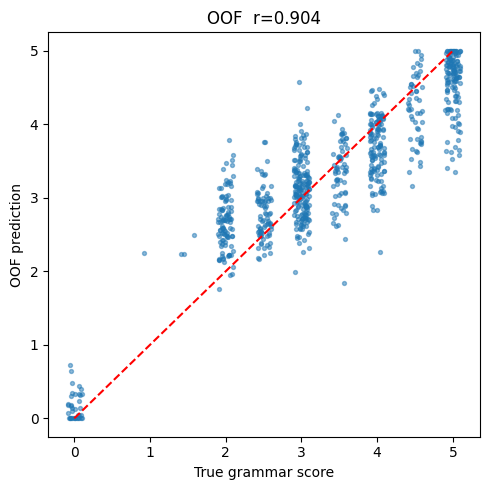

(216, 2) {'count': 216.0, 'mean': 3.282, 'std': 0.759, 'min': 1.771, '25%': 2.692, '50%': 3.164, '75%': 3.732, 'max': 5.0}
sample_submission rows=204, filename overlap with test.csv=25
        filename     label
0  audio_128.wav  2.724384
1  audio_156.wav  3.536885
2   audio_19.wav  4.739292
3  audio_108.wav  1.990935
4  audio_206.wav  2.138025


In [36]:

try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(5, 5))
    plt.scatter(y + np.random.uniform(-0.1, 0.1, len(y)), blend_oof, s=8, alpha=0.5)
    plt.plot([0, 5], [0, 5], "r--"); plt.xlabel("True grammar score"); plt.ylabel("OOF prediction")
    plt.title(f"OOF  r={pearsonr(y, blend_oof)[0]:.3f}"); plt.tight_layout()
    plt.savefig(WORK / "oof_scatter.png", dpi=120); plt.show()
except Exception:
    pass
 
# %% 9) Submission
sub = pd.DataFrame({"filename": test_df.filename, "label": blend_te})
sub.to_csv(WORK / "submission.csv", index=False)
print(sub.shape, sub.label.describe().round(3).to_dict())
if "sample_submission.csv" in csv_files:
    ss = pd.read_csv(csv_files["sample_submission.csv"])
    overlap = len(set(ss.filename) & set(sub.filename))
    print(f"sample_submission rows={len(ss)}, filename overlap with test.csv={overlap}")
print(sub.head())